# NYC 311 Complaints and Weather

This notebook looks at how New York City 311 complaints change with the weather and the calendar.

**Steps**
1. Load the data and count complaints per day
2. Pick 8 complaint types to study
3. How many complaints of each type there are
4. Complaints vs. temperature (one standalone graph per complaint type)
5. Rate ratios by weather condition, day of the week, holiday, and month
6. An XGBoost model that predicts each complaint type's daily count
7. The features that matter most to the model

Weather comes from the **Central Park** station (the `CP_` columns).

## 1. Setup

In [153]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

In [154]:
# Colors used in every chart
BLUE = "#2a78d6"
LIGHT_BLUE = "#86b6ef"
DARK_BLUE = "#1c5cab"
ORANGE = "#eb6834"
RED = "#e34948"
INK = "#0b0b0b"
MUTED_INK = "#52514e"

# A clean, simple chart style
plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelcolor": MUTED_INK,
    "xtick.color": MUTED_INK,
    "ytick.color": MUTED_INK,
    "text.color": INK,
    "legend.frameon": False,
})

## 2. Load the data

The CSV has one row per complaint (about 22 million rows, ~7 GB), which is too big to load at once.
So we read it in chunks and keep only what we need:

* the **number of complaints of each type on each day**, and
* the **weather on each day** (it is the same for every complaint made that day).

Both results are small, so we save them as CSV files. The first run takes a few minutes;
after that the notebook loads the saved files in seconds.
(Delete `daily_complaint_type_counts.csv` and `daily_weather.csv` to rebuild them.)

In [155]:
DATA_FILE = "ComplaintsWeather.csv"
COUNTS_FILE = "daily_complaint_type_counts.csv"   # saved summary: complaints per type per day
WEATHER_FILE = "daily_weather.csv"                 # saved summary: weather per day

TYPE_COLUMN = "Problem (formerly Complaint Type)"

# Columns that describe the day -> shorter, easier names
DAY_COLUMNS = {
    "IS_HOLIDAY": "is_holiday",
    "CP_TAVG": "avg_temp_F",
    "CP_TMAX": "max_temp_F",
    "CP_TMIN": "min_temp_F",
    "CP_PRCP": "precip_in",
    "CP_PRCP_TRACE": "trace_precip",
    "CP_SNOW": "snowfall_in",
    "CP_SNOW_TRACE": "trace_snow",
    "CP_SNWD": "snow_depth_in",
    "CP_AWND": "avg_wind_mph",
    "CP_WSF5": "max_gust_mph",
}

In [156]:
type_counts = pd.read_csv(COUNTS_FILE)
weather = pd.read_csv(WEATHER_FILE)

In [157]:
weather.head()

,date,is_holiday,avg_temp_F,max_temp_F,min_temp_F,precip_in,trace_precip,snowfall_in,trace_snow,snow_depth_in,avg_wind_mph,max_gust_mph
0,2020-01-01,1,37.49,41.00,33.98,0.000000,0,0.0,0,0.0,8.500372,29.080220
1,2020-01-02,0,41.00,48.92,33.08,0.000000,0,0.0,0,0.0,5.368656,21.922012
2,2020-01-03,0,46.49,48.92,44.06,0.149606,0,0.0,0,0.0,3.355410,14.987498
3,2020-01-04,0,46.04,51.08,41.00,0.271654,0,0.0,0,0.0,4.473880,23.935258
4,2020-01-05,0,38.57,42.08,35.06,0.000000,1,0.0,0,0.0,11.408394,42.949248


## 3. The 8 complaint types we study

There are 247 complaint types, and many of them have only a handful of complaints.
We study 8 types that we expect to react to the weather or the calendar in different ways. Each one gets a short column name:

| Column | 311 complaint type | Why it is interesting |
|---|---|---|
| `Heat` | HEAT/HOT WATER | should go up when it is cold |
| `StreetNoise` | Noise - Street/Sidewalk | people are outside when it is warm |
| `ResidentialNoise` | Noise - Residential | parties, weekends |
| `IllegalParking` | Illegal Parking | the biggest type, probably not weather related |
| `DamagedTree` | Damaged Tree | storms and wind |
| `Sewer` | Sewer | heavy rain |
| `SnowIce` | Snow or Ice | snow |
| `Fireworks` | Illegal Fireworks | July 4th |

In [158]:
# 311 complaint type -> short column name
COMPLAINT_TYPES = {
    "HEAT/HOT WATER": "Heat",
    "Noise - Street/Sidewalk": "StreetNoise",
    "Noise - Residential": "ResidentialNoise",
    "Illegal Parking": "IllegalParking",
    "Damaged Tree": "DamagedTree",
    "Sewer": "Sewer",
    "Snow or Ice": "SnowIce",
    "Illegal Fireworks": "Fireworks",
}

TYPES = list(COMPLAINT_TYPES.values())     # the 8 short column names, used everywhere below
TYPES

['Heat',
 'StreetNoise',
 'ResidentialNoise',
 'IllegalParking',
 'DamagedTree',
 'Sewer',
 'SnowIce',
 'Fireworks']

### Build the daily table

One row per day, with the number of complaints of each of the 8 types, the weather, and calendar information.

**End date.** In this data pull, Sewer complaints stop on **July 29, 2026**: there is at least one every day until then and none after.
Other complaint types handled by the Department of Environmental Protection (like Water System) stop on the same day,
so the last month of their data is missing, not zero. If we kept August 2026, those days would look like days with 0 sewer complaints,
so the study ends on July 29, 2026 for all 8 types.

In [159]:
# end the study on the last day Sewer complaints are in the data (see above)
END_DATE = "2026-07-29"
type_counts = type_counts[type_counts["date"] <= END_DATE]
weather = weather[weather["date"] <= END_DATE]

# keep only our 8 types and give each one its short column name
our_types = type_counts[type_counts["complaint_type"].isin(list(COMPLAINT_TYPES.keys()))].copy()
our_types["column"] = our_types["complaint_type"].map(COMPLAINT_TYPES)

# complaints of each type per day (a day with no complaints of a type gets 0)
daily_counts = our_types.pivot_table(
    index="date", columns="column", values="count", aggfunc="sum", fill_value=0
)
daily_counts = daily_counts[TYPES].reset_index()

daily = weather.merge(daily_counts, on="date", how="left")
daily[TYPES] = daily[TYPES].fillna(0)
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values("date").reset_index(drop=True)

# calendar columns
daily["year"] = daily["date"].dt.year
daily["month"] = daily["date"].dt.month
daily["day_of_week"] = daily["date"].dt.dayofweek        # 0 = Monday ... 6 = Sunday
daily["day_name"] = daily["date"].dt.day_name()
daily["day_of_year"] = daily["date"].dt.dayofyear
daily["is_weekend"] = (daily["day_of_week"] >= 5).astype(int)

print(daily.shape, "from", daily["date"].min().date(), "to", daily["date"].max().date())
daily.head()

(2402, 26) from 2020-01-01 to 2026-07-29


,date,is_holiday,avg_temp_F,max_temp_F,min_temp_F,precip_in,trace_precip,snowfall_in,trace_snow,snow_depth_in,avg_wind_mph,max_gust_mph,Heat,StreetNoise,ResidentialNoise,IllegalParking,DamagedTree,Sewer,SnowIce,Fireworks,year,month,day_of_week,day_name,day_of_year,is_weekend
0,2020-01-01,1,37.49,41.00,33.98,0.000000,0,0.0,0,0.0,8.500372,29.080220,692,149,1166,427,11,42,0,8,2020,1,2,Wednesday,1,0
1,2020-01-02,0,41.00,48.92,33.08,0.000000,0,0.0,0,0.0,5.368656,21.922012,673,109,427,599,31,77,2,2,2020,1,3,Thursday,2,0
2,2020-01-03,0,46.49,48.92,44.06,0.149606,0,0.0,0,0.0,3.355410,14.987498,533,80,594,623,26,68,0,0,2020,1,4,Friday,3,0
3,2020-01-04,0,46.04,51.08,41.00,0.271654,0,0.0,0,0.0,4.473880,23.935258,554,137,747,482,16,65,0,0,2020,1,5,Saturday,4,1
4,2020-01-05,0,38.57,42.08,35.06,0.000000,1,0.0,0,0.0,11.408394,42.949248,746,78,848,491,39,30,0,0,2020,1,6,Sunday,5,1


### Weather condition columns

Each weather condition gets **its own 0/1 column** (1 = the day had that condition), so a day can have more than one condition,
for example a snowy day that is also freezing, or a rainy day that is also windy.
This keeps more detail than putting every day into a single group, and the XGBoost model in section 7 can use each column as a feature.

| Column | Rule (Central Park) |
|---|---|
| `is_snow` | any measurable snowfall |
| `is_freezing` | high of 32°F or less |
| `is_heavy_rain` | 1 inch or more of precipitation, and no snow |
| `is_rain` | 0.1 to 1 inch of precipitation, and no snow |
| `is_windy` | wind gust of 40 mph or more |
| `is_hot` | high of 90°F or more |
| `is_normal_weather` | none of the above (the comparison group for the rate ratios) |

The two rain columns leave out snow days because the precipitation number also includes melted snow,
so a big snowstorm would otherwise count as "heavy rain".

In [160]:
no_snow = daily["snowfall_in"] == 0

daily["is_snow"] = (daily["snowfall_in"] > 0).astype(int)
daily["is_freezing"] = (daily["max_temp_F"] <= 32).astype(int)
daily["is_heavy_rain"] = (no_snow & (daily["precip_in"] >= 1.0)).astype(int)
daily["is_rain"] = (no_snow & (daily["precip_in"] >= 0.1) & (daily["precip_in"] < 1.0)).astype(int)
daily["is_windy"] = (daily["max_gust_mph"] >= 40).astype(int)
daily["is_hot"] = (daily["max_temp_F"] >= 90).astype(int)

WEATHER_CONDITIONS = ["is_snow", "is_freezing", "is_heavy_rain", "is_rain", "is_windy", "is_hot"]

# normal weather = none of the six conditions
daily["is_normal_weather"] = (daily[WEATHER_CONDITIONS].sum(axis=1) == 0).astype(int)

# number of days with each condition (a day can be counted in more than one)
daily[WEATHER_CONDITIONS + ["is_normal_weather"]].sum()

is_snow                59
is_freezing            76
is_heavy_rain          70
is_rain               408
is_windy               70
is_hot                 83
is_normal_weather    1706
dtype: int64

## 4. How many complaints of each type?

In [161]:
totals = daily[TYPES].sum()
all_complaints = type_counts["count"].sum()

summary = pd.DataFrame({
    "311 complaint type": list(COMPLAINT_TYPES.keys()),
    "total complaints": totals,
    "share of all complaints (%)": (100 * totals / all_complaints).round(1),
    "average per day": daily[TYPES].mean().round(0),
})
summary.sort_values("total complaints", ascending=False)

,311 complaint type,total complaints,share of all complaints (%),average per day
IllegalParking,Illegal Parking,2837579,13.0,1181.0
ResidentialNoise,Noise - Residential,2505013,11.4,1043.0
Heat,HEAT/HOT WATER,1647642,7.5,686.0
StreetNoise,Noise - Street/Sidewalk,1127659,5.1,469.0
DamagedTree,Damaged Tree,237956,1.1,99.0
Sewer,Sewer,191038,0.9,80.0
Fireworks,Illegal Fireworks,122514,0.6,51.0
SnowIce,Snow or Ice,95075,0.4,40.0


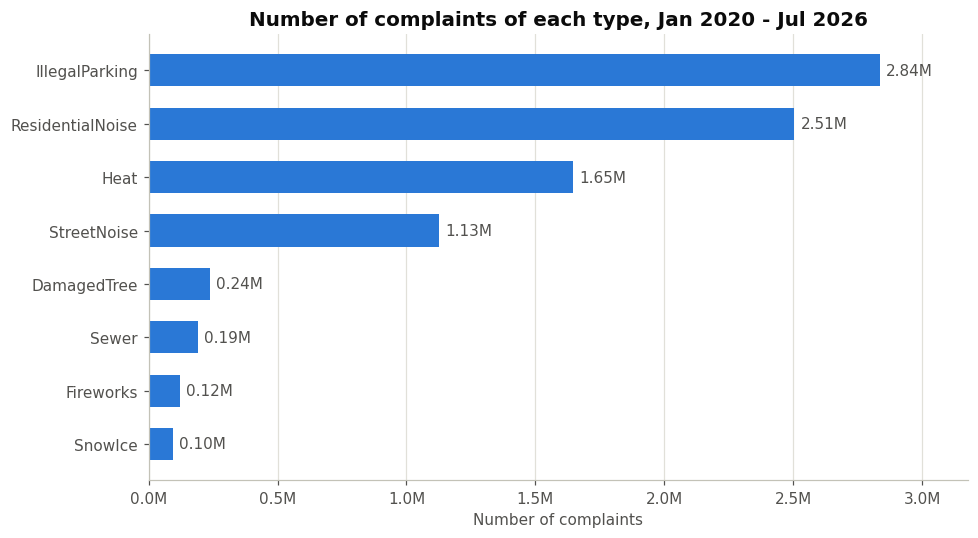

In [162]:
sorted_totals = totals.sort_values()     # smallest first, so the biggest bar ends up on top

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(sorted_totals.index, sorted_totals.values, color=BLUE, height=0.6)

labels = [f"{total / 1e6:.2f}M" for total in sorted_totals.values]
ax.bar_label(bars, labels=labels, padding=4, color=MUTED_INK)

ax.set_title("Number of complaints of each type, Jan 2020 - Jul 2026")
ax.set_xlabel("Number of complaints")
ax.xaxis.set_major_formatter(lambda value, position: f"{value / 1e6:.1f}M")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, sorted_totals.max() * 1.12)
plt.tight_layout()
plt.show()

## 5. Complaints vs. temperature

One graph per complaint type. Each dot is a day; the dark line is the average number of complaints
for each 5°F band of temperature (bands with fewer than 10 days are left off the line).

**Hiding the extreme days.** For **StreetNoise**, **ResidentialNoise**, **DamagedTree**, **Sewer**, and **Fireworks**, a few extreme days
stretch the y-axis so much that all the normal days get squashed at the bottom. For example, DamagedTree is usually around 60 complaints a day,
but it reached 13,955 on Aug 4, 2020 (Tropical Storm Isaias), and Fireworks reached 6,121 on July 4, 2020.
For these five graphs we zoom in: the y-axis stops at the **99th percentile**, so the busiest 1% of days (about 25 days)
are above the top of the chart. Those days are still used to calculate the average line and the correlation.

Heat, IllegalParking, and SnowIce are shown in full. Heat and IllegalParking have no extreme outliers, and for SnowIce the zoom
would cut off the average line on the coldest days, which is the pattern we want to see.

Every graph is also saved as its own PNG in the `figures` folder so it can be used on its own.

In [189]:
os.makedirs("figures", exist_ok=True)


def plot_temperature(column, hide_outliers=False):
    fig, ax = plt.subplots(figsize=(8, 5))

    # every day as a dot
    ax.scatter(daily["avg_temp_F"], daily[column], s=10, color=LIGHT_BLUE, alpha=0.5,
               edgecolors="none", label="One day")

    # average for each 5°F band (only bands with at least 10 days)
    temperature_band = (daily["avg_temp_F"] // 5) * 5 + 2.5      # middle of the band
    band_average = daily.groupby(temperature_band)[column].mean()
    band_days = daily.groupby(temperature_band)[column].size()
    band_average = band_average[band_days >= 10]
    ax.plot(band_average.index, band_average.values, color=DARK_BLUE, linewidth=2,
            marker="o", markersize=5, label="Average for each 5°F band")

    correlation = daily["avg_temp_F"].corr(daily[column])
    note = f"correlation r = {correlation:.2f}"

    if hide_outliers:
        # zoom in: the y-axis stops at the 99th percentile, so the busiest 1% of days are off the chart
        top = daily[column].quantile(0.97)
        ax.set_ylim(0, top)
        days_hidden = (daily[column] > top).sum()
        note = note + f"\n{days_hidden} busiest days are above the chart"
    else:
        ax.set_ylim(bottom=0)

    ax.set_title(f"{column}: complaints per day vs. temperature")
    ax.text(0.99, 0.97, note, transform=ax.transAxes, ha="right", va="top", color=MUTED_INK)
    ax.set_xlabel("Average daily temperature (°F, Central Park)")
    ax.set_ylabel("Complaints per day")
    ax.legend(loc="upper left")
    plt.tight_layout()

    fig.savefig(f"figures/temperature_{column}.png", dpi=150)
    plt.show()

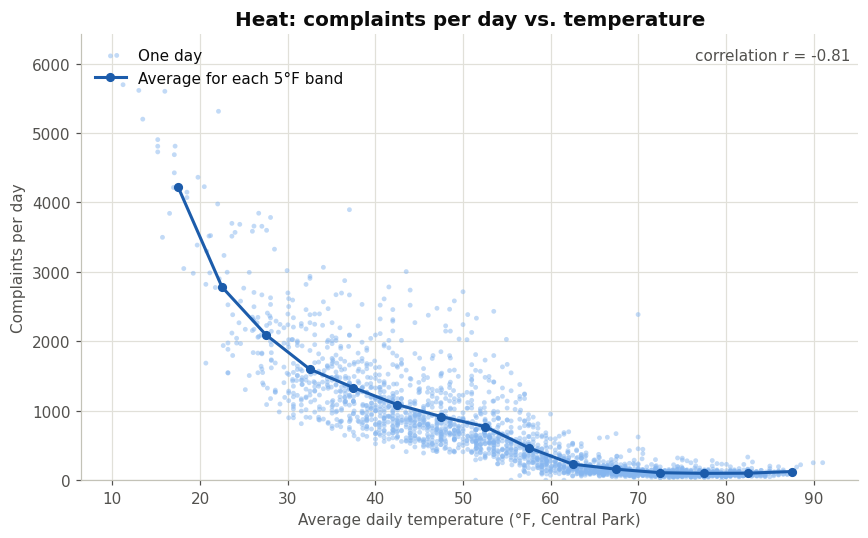

In [190]:
plot_temperature("Heat")

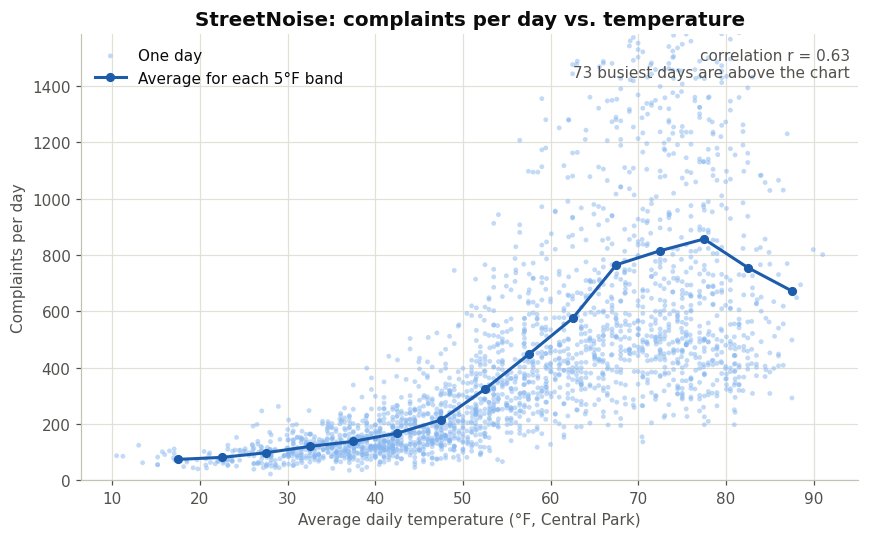

In [191]:
plot_temperature("StreetNoise", hide_outliers=True)

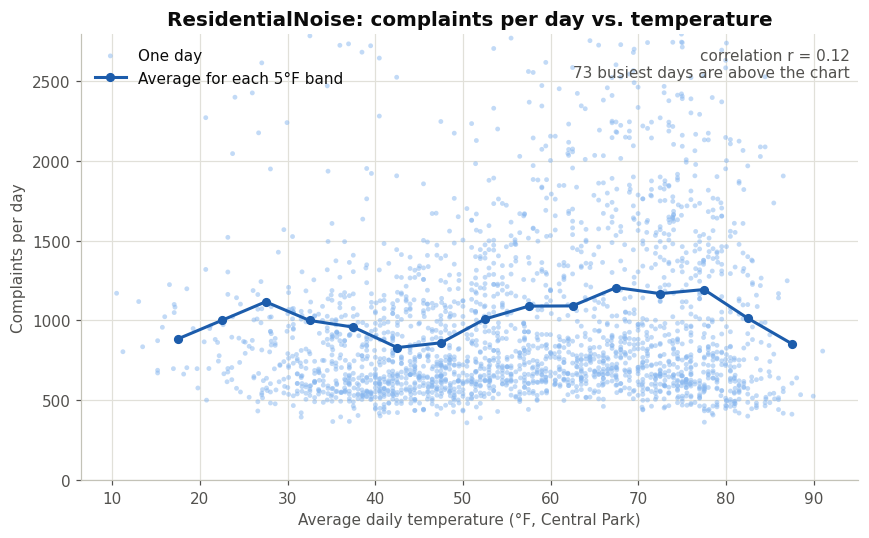

In [192]:
plot_temperature("ResidentialNoise", hide_outliers=True)

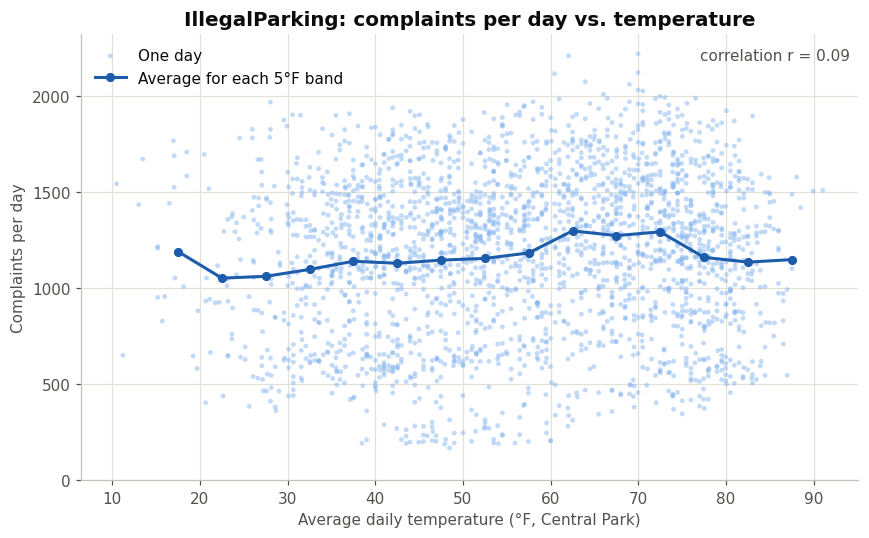

In [193]:
plot_temperature("IllegalParking")

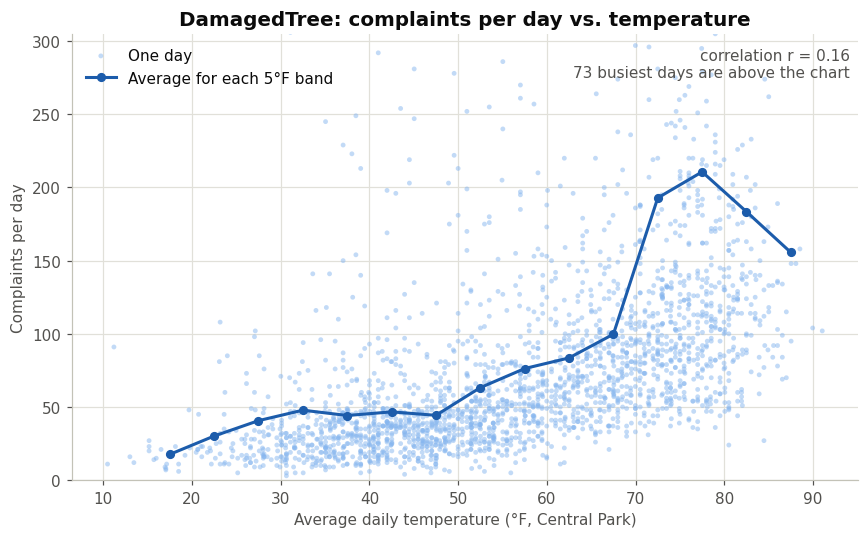

In [194]:
plot_temperature("DamagedTree", hide_outliers=True)

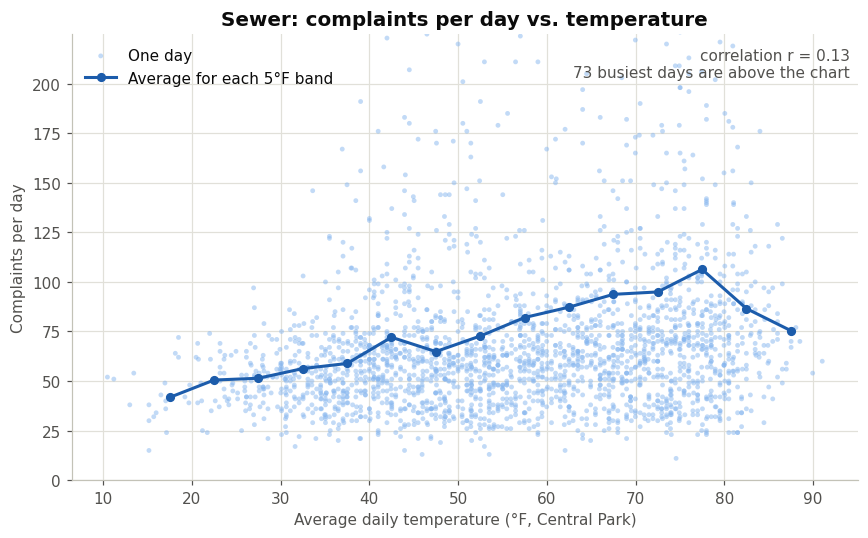

In [195]:
plot_temperature("Sewer", hide_outliers=True)

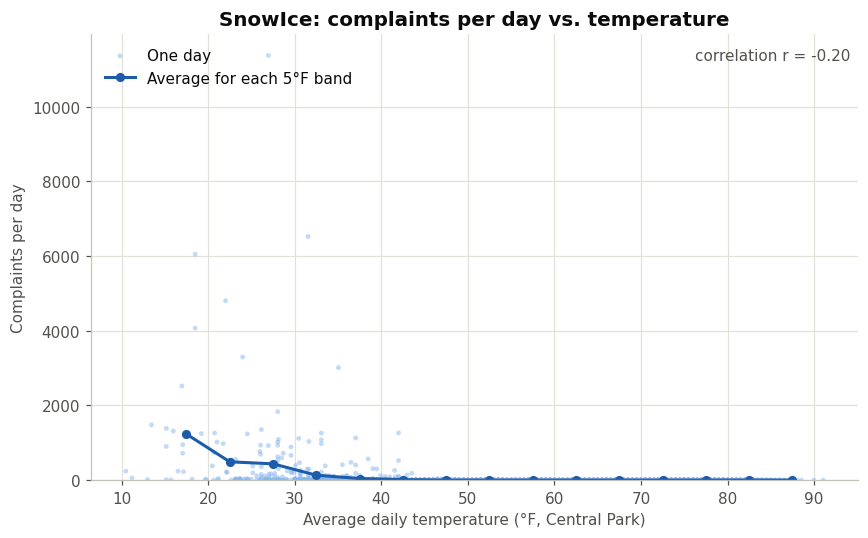

In [196]:
plot_temperature("SnowIce")

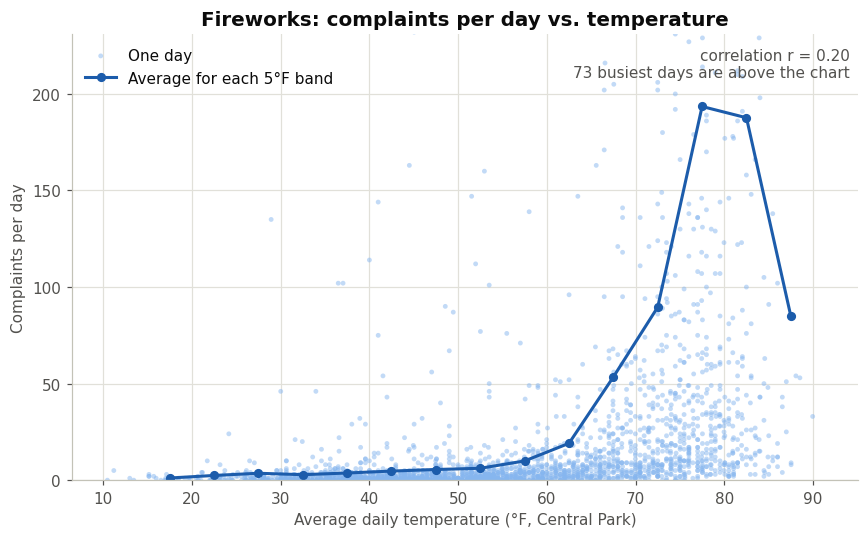

In [197]:
plot_temperature("Fireworks", hide_outliers=True)

## 6. Rate ratios

A **rate ratio** compares the average number of complaints per day in one group of days with a baseline:

$$\text{rate ratio} = \frac{\text{average complaints per day in the group}}{\text{average complaints per day in the baseline}}$$

* **1.00** means no difference, **1.25** means 25% more complaints per day, **0.80** means 20% fewer.

The heatmaps are drawn with **seaborn** (`sns.heatmap`), which does all the work in one line:

* `annot=True, fmt=".2f"` writes the rate ratio (2 decimals) in every cell.
* `cmap="coolwarm", center=1` colors the cells: 1 (no difference) is gray, **red = more complaints** than the baseline, **blue = fewer**.
* `vmin=0.5, vmax=1.5` uses the same color scale in every heatmap: 1.5 or more is the darkest red and 0.5 or less is the darkest blue.
  The number in the cell always shows the exact value.

These are simple comparisons: they do not adjust for other factors (for example, snow days are also winter days).
The XGBoost model in section 7 looks at all of the factors together.

In [198]:
def rate_ratio_table(group_column, reference=None):
    # average complaints per day for each group of days
    rates = daily.groupby(group_column)[TYPES].mean()

    # baseline: one group (if given) or the average over all days
    if reference is None:
        baseline = daily[TYPES].mean()
    else:
        baseline = rates.loc[reference]

    ratios = rates / baseline
    return ratios.T          # rows = complaint types, columns = groups


def plot_rate_ratio_heatmap(table, title, xlabel):
    plt.figure(figsize=(10, 5.5))
    sns.heatmap(table, annot=True, fmt=".2f", cmap="coolwarm", center=1, vmin=0.5, vmax=1.5,
                cbar_kws={"label": "Rate ratio"})
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("")
    plt.show()

### 6a. Weather condition

Baseline: **normal-weather days** (`is_normal_weather` = 1, so none of the six conditions).
Each column compares the days that have one condition with the normal-weather days.
Because each condition has its own column, a day can be counted in more than one column
(for example, a snowy day with a high below 32°F is in both **Snow** and **Freezing**).

In [199]:
normal_days = daily[daily["is_normal_weather"] == 1]

weather_ratios = pd.DataFrame()
for condition in WEATHER_CONDITIONS:
    condition_days = daily[daily[condition] == 1]
    weather_ratios[condition] = condition_days[TYPES].mean() / normal_days[TYPES].mean()

weather_ratios.round(2)

,is_snow,is_freezing,is_heavy_rain,is_rain,is_windy,is_hot
Heat,2.85,4.86,0.89,0.82,2.00,0.18
StreetNoise,0.20,0.16,0.57,0.71,0.46,1.42
ResidentialNoise,0.96,0.96,0.82,0.88,0.90,0.89
IllegalParking,0.85,0.89,0.88,0.93,0.96,0.94
DamagedTree,0.77,0.40,2.49,1.88,4.51,2.32
Sewer,0.85,0.75,5.04,1.64,1.94,1.37
SnowIce,31.72,64.29,0.04,0.08,10.25,0.00
Fireworks,0.11,0.04,0.34,1.15,0.62,3.74


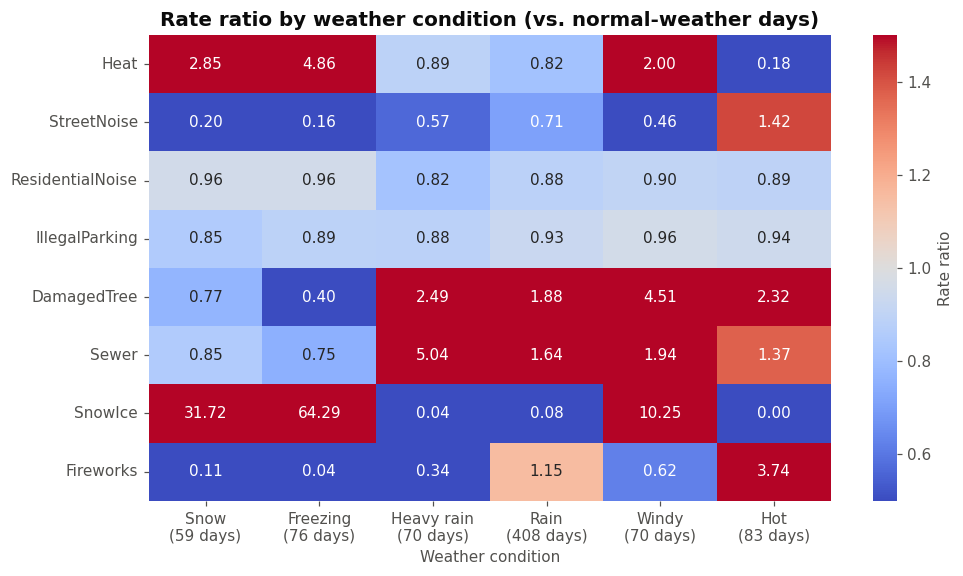

In [200]:
# nicer column names that also show the number of days, e.g. "Snow (59 days)"
condition_names = ["Snow", "Freezing", "Heavy rain", "Rain", "Windy", "Hot"]
days_per_condition = daily[WEATHER_CONDITIONS].sum()
weather_ratios.columns = [f"{name}\n({days} days)" for name, days in zip(condition_names, days_per_condition)]

plot_rate_ratio_heatmap(
    weather_ratios,
    title="Rate ratio by weather condition (vs. normal-weather days)",
    xlabel="Weather condition",
)

### 6b. Day of the week

Baseline: the **average day**, so 1.10 means a typical Monday (for example) has 10% more complaints than the average day.

In [201]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

weekday_ratios = rate_ratio_table("day_name")[weekday_order]
weekday_ratios.round(2)

day_name,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
Heat,1.11,1.08,0.99,0.95,0.94,0.96,0.97
StreetNoise,0.80,0.66,0.66,0.71,0.98,1.52,1.67
ResidentialNoise,0.87,0.76,0.72,0.73,0.90,1.47,1.55
IllegalParking,1.01,1.04,1.02,1.04,1.02,0.92,0.97
DamagedTree,1.13,1.42,1.18,1.02,0.98,0.66,0.61
Sewer,1.14,1.09,1.05,1.22,1.13,0.71,0.65
SnowIce,1.74,2.00,1.09,0.69,0.44,0.39,0.65
Fireworks,0.87,0.72,0.63,0.73,0.92,1.57,1.57


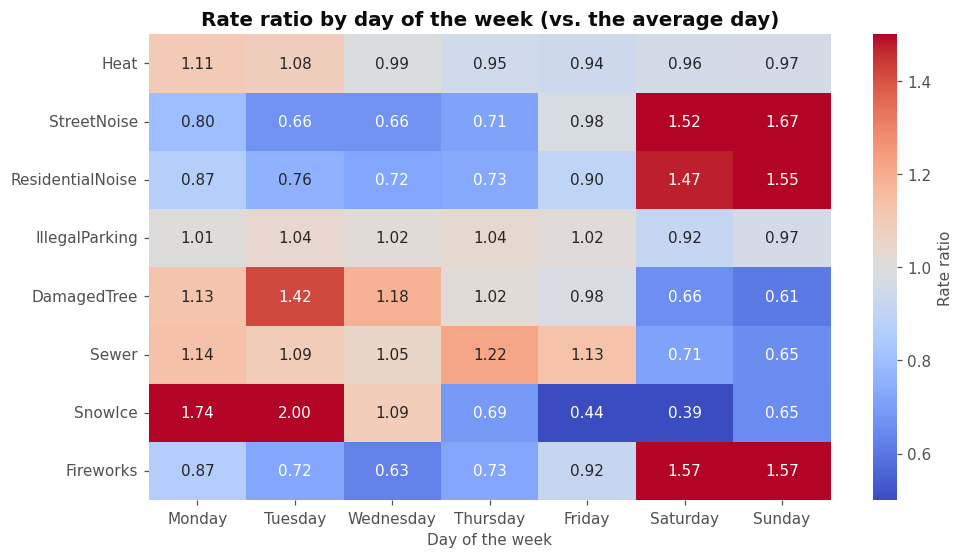

In [202]:
plot_rate_ratio_heatmap(
    weekday_ratios,
    title="Rate ratio by day of the week (vs. the average day)",
    xlabel="Day of the week",
)

### 6c. Holiday vs. not a holiday

Holidays are the federal holidays flagged in the data (`IS_HOLIDAY`): New Year's Day, MLK Day, Presidents' Day, Memorial Day,
Juneteenth, Independence Day, Labor Day, Columbus Day, Veterans Day, Thanksgiving, and Christmas.

We compare the average holiday with two baselines:
1. **all other days** (every day that is not a holiday), and
2. **ordinary weekdays** (Monday - Friday days that are not holidays). This is a fairer comparison, because every holiday in the data
   falls on a weekday, while "all other days" also includes the weekends.

In [203]:
holidays = daily[daily["is_holiday"] == 1]
other_days = daily[daily["is_holiday"] == 0]
ordinary_weekdays = daily[(daily["is_holiday"] == 0) & (daily["is_weekend"] == 0)]

holiday_ratios = pd.DataFrame({
    "vs. all other days": holidays[TYPES].mean() / other_days[TYPES].mean(),
    "vs. ordinary weekdays": holidays[TYPES].mean() / ordinary_weekdays[TYPES].mean(),
})
holiday_ratios.round(2)

,vs. all other days,vs. ordinary weekdays
Heat,1.15,1.14
StreetNoise,1.24,1.65
ResidentialNoise,1.20,1.53
IllegalParking,0.85,0.82
DamagedTree,0.87,0.75
Sewer,0.76,0.67
SnowIce,0.87,0.72
Fireworks,5.45,8.06


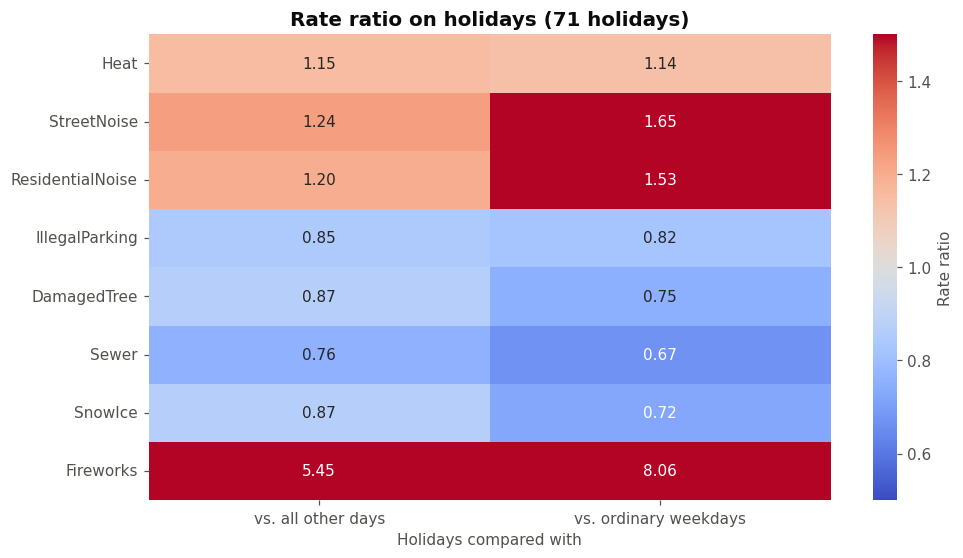

In [204]:
plot_rate_ratio_heatmap(
    holiday_ratios,
    title=f"Rate ratio on holidays ({len(holidays)} holidays)",
    xlabel="Holidays compared with",
)

In [205]:
print("Holidays by day of the week:", holidays["day_name"].value_counts().to_dict())

winter_months = [11, 12, 1, 2]
print(f"Days that are in Nov - Feb: {holidays['month'].isin(winter_months).mean():.0%} of holidays, "
      f"{other_days['month'].isin(winter_months).mean():.0%} of other days")

# the 5 holidays with the most fireworks complaints
holidays.nlargest(5, "Fireworks")[["date", "day_name", "Fireworks"]]

Holidays by day of the week: {'Monday': 42, 'Friday': 11, 'Thursday': 11, 'Wednesday': 5, 'Tuesday': 2}
Days that are in Nov - Feb: 55% of holidays, 32% of other days


,date,day_name,Fireworks
2011,2025-07-04,Friday,3134
1280,2023-07-04,Tuesday,2759
1646,2024-07-04,Thursday,2746
915,2022-07-04,Monday,2232
551,2021-07-05,Monday,1721


**How to read the holiday results**

Each cell compares the average holiday with a baseline: red means more complaints on holidays, blue means fewer.
All 71 holidays fall on a weekday (42 of them are Mondays), so the second column, which compares them with ordinary weekdays only, is the fairer one.

* **Fireworks has by far the biggest holiday effect (5.45×), and it is almost all July 4th.** The five holidays with the most fireworks complaints
  (table above) are all Independence Day. Compared with ordinary weekdays, holidays have 8× as many fireworks complaints.
* **Noise works like a weekend.** StreetNoise (1.24) and ResidentialNoise (1.20) go up on holidays because people are off work, at home,
  and celebrating. Compared with ordinary weekdays the effect is bigger (1.65 and 1.53), almost the same as a Saturday or Sunday in section 6b.
* **Complaints that people report during the work week go down.** Sewer (0.76), DamagedTree (0.87), and IllegalParking (0.85) are lower on holidays,
  and lower still compared with ordinary weekdays (0.67, 0.75, and 0.82). Sewer and DamagedTree also drop on weekends (6b),
  so a holiday looks like a weekend day for them: fewer people are out commuting to notice and report problems.
* **Heat (1.15) comes from the season, not the holiday.** 55% of holidays are in November - February (New Year's, MLK Day, Presidents' Day,
  Veterans Day, Thanksgiving, Christmas), compared with 32% of other days, and heat complaints are about twice the average in those months (section 6d).
  The two columns give almost the same number for Heat (1.15 and 1.14) because heat complaints barely depend on the day of the week.
* **SnowIce (0.87)** depends on whether a snowstorm happened to land on a holiday, so with only 71 holidays this number doesn't say much.

### 6d. Month

Baseline: the **average day** across the whole data set.
(January - July include 2026, August - December do not.)

In [206]:
month_ratios = rate_ratio_table("month")
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
month_ratios.columns = month_names
month_ratios.round(2)

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Heat,2.36,1.79,1.13,0.75,0.35,0.16,0.14,0.12,0.18,1.01,1.88,2.22
StreetNoise,0.26,0.28,0.54,0.78,1.37,1.91,1.70,1.60,1.48,1.11,0.62,0.34
ResidentialNoise,0.94,0.80,0.79,0.87,1.13,1.06,1.07,1.03,1.28,1.10,0.95,1.03
IllegalParking,0.92,0.95,1.02,0.98,1.07,1.10,0.98,0.92,1.07,1.03,1.01,0.95
DamagedTree,0.34,0.45,0.49,0.57,0.88,1.45,1.68,3.33,1.10,0.79,0.57,0.48
Sewer,0.77,0.73,0.91,0.82,1.01,0.96,1.30,1.19,1.80,1.03,0.77,0.79
SnowIce,4.32,5.63,0.04,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.01,1.82
Fireworks,0.14,0.06,0.06,0.09,0.32,4.33,5.47,0.32,0.24,0.16,0.12,0.11


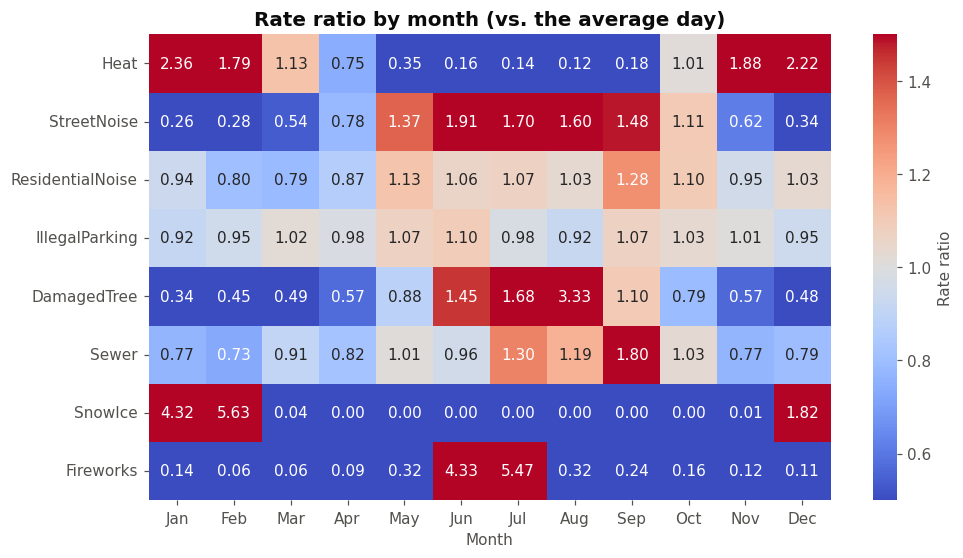

In [207]:
plot_rate_ratio_heatmap(
    month_ratios,
    title="Rate ratio by month (vs. the average day)",
    xlabel="Month",
)

## 7. XGBoost: predict each complaint type's daily count

We train **one XGBoost model per complaint type** (8 models). Each model gets the same information about a day:

* **Weather:** temperature (average, high, low), precipitation, snowfall, snow on the ground, wind, gusts,
  yesterday's precipitation and snowfall, and the **six 0/1 weather condition columns** from section 3
  (`is_snow`, `is_freezing`, `is_heavy_rain`, `is_rain`, `is_windy`, `is_hot`)
* **Calendar:** day of the week, month, day of the year, weekend, holiday, and year (311 use changes over time)

To test the models fairly, we train on the earlier days and test on the **last 365 days**, which the models never see while training.

Because we are predicting **counts**, the models use XGBoost's Poisson objective (`count:poisson`).
It is built for count data and keeps the models from over-reacting to a few extreme days in the training data.

In [208]:
# yesterday's weather can matter too (for example, snow that fell overnight)
daily["precip_yesterday_in"] = daily["precip_in"].shift(1)
daily["snowfall_yesterday_in"] = daily["snowfall_in"].shift(1)

FEATURES = [
    "avg_temp_F", "max_temp_F", "min_temp_F",
    "precip_in", "trace_precip", "snowfall_in", "trace_snow", "snow_depth_in",
    "avg_wind_mph", "max_gust_mph",
    "precip_yesterday_in", "snowfall_yesterday_in",
    "is_snow", "is_freezing", "is_heavy_rain", "is_rain", "is_windy", "is_hot",
    "day_of_week", "month", "day_of_year", "is_weekend", "is_holiday", "year",
]

test_start = daily["date"].max() - pd.Timedelta(days=364)
train = daily[daily["date"] < test_start]
test = daily[daily["date"] >= test_start]

print(f"Training days: {len(train)}  ({train['date'].min().date()} to {train['date'].max().date()})")
print(f"Testing days:  {len(test)}  ({test['date'].min().date()} to {test['date'].max().date()})")

Training days: 2037  (2020-01-01 to 2025-07-29)
Testing days:  365  (2025-07-30 to 2026-07-29)


In [209]:
models = {}
predictions = pd.DataFrame({"date": test["date"]})
scores = []

for complaint_type in TYPES:
    model = XGBRegressor(
        objective="count:poisson",     # made for predicting counts
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        importance_type="gain",
        random_state=42,
    )
    model.fit(train[FEATURES], train[complaint_type])

    predicted = model.predict(test[FEATURES])
    predictions[complaint_type] = predicted
    models[complaint_type] = model

    actual = test[complaint_type]
    scores.append({
        "complaint type": complaint_type,
        "average per day (test)": actual.mean(),
        "MAE": mean_absolute_error(actual, predicted),
        "R²": r2_score(actual, predicted),
    })

scores = pd.DataFrame(scores).set_index("complaint type")
scores["MAE as % of average"] = 100 * scores["MAE"] / scores["average per day (test)"]
scores.round(2)

,average per day (test),MAE,R²,MAE as % of average
complaint type,,,,
Heat,978.17,165.08,0.92,16.88
StreetNoise,482.29,73.70,0.91,15.28
ResidentialNoise,1201.11,362.93,-0.16,30.22
IllegalParking,1665.38,155.97,0.16,9.37
DamagedTree,112.13,53.97,0.22,48.13
Sewer,86.24,32.57,0.22,37.77
SnowIce,175.16,140.99,0.14,80.50
Fireworks,30.59,17.26,0.64,56.42


**How to read this:** MAE (mean absolute error) is how many complaints the prediction is off by on a typical day.
R² is the share of the day-to-day variation the model explains (1 = perfect, 0 = no better than guessing the average).

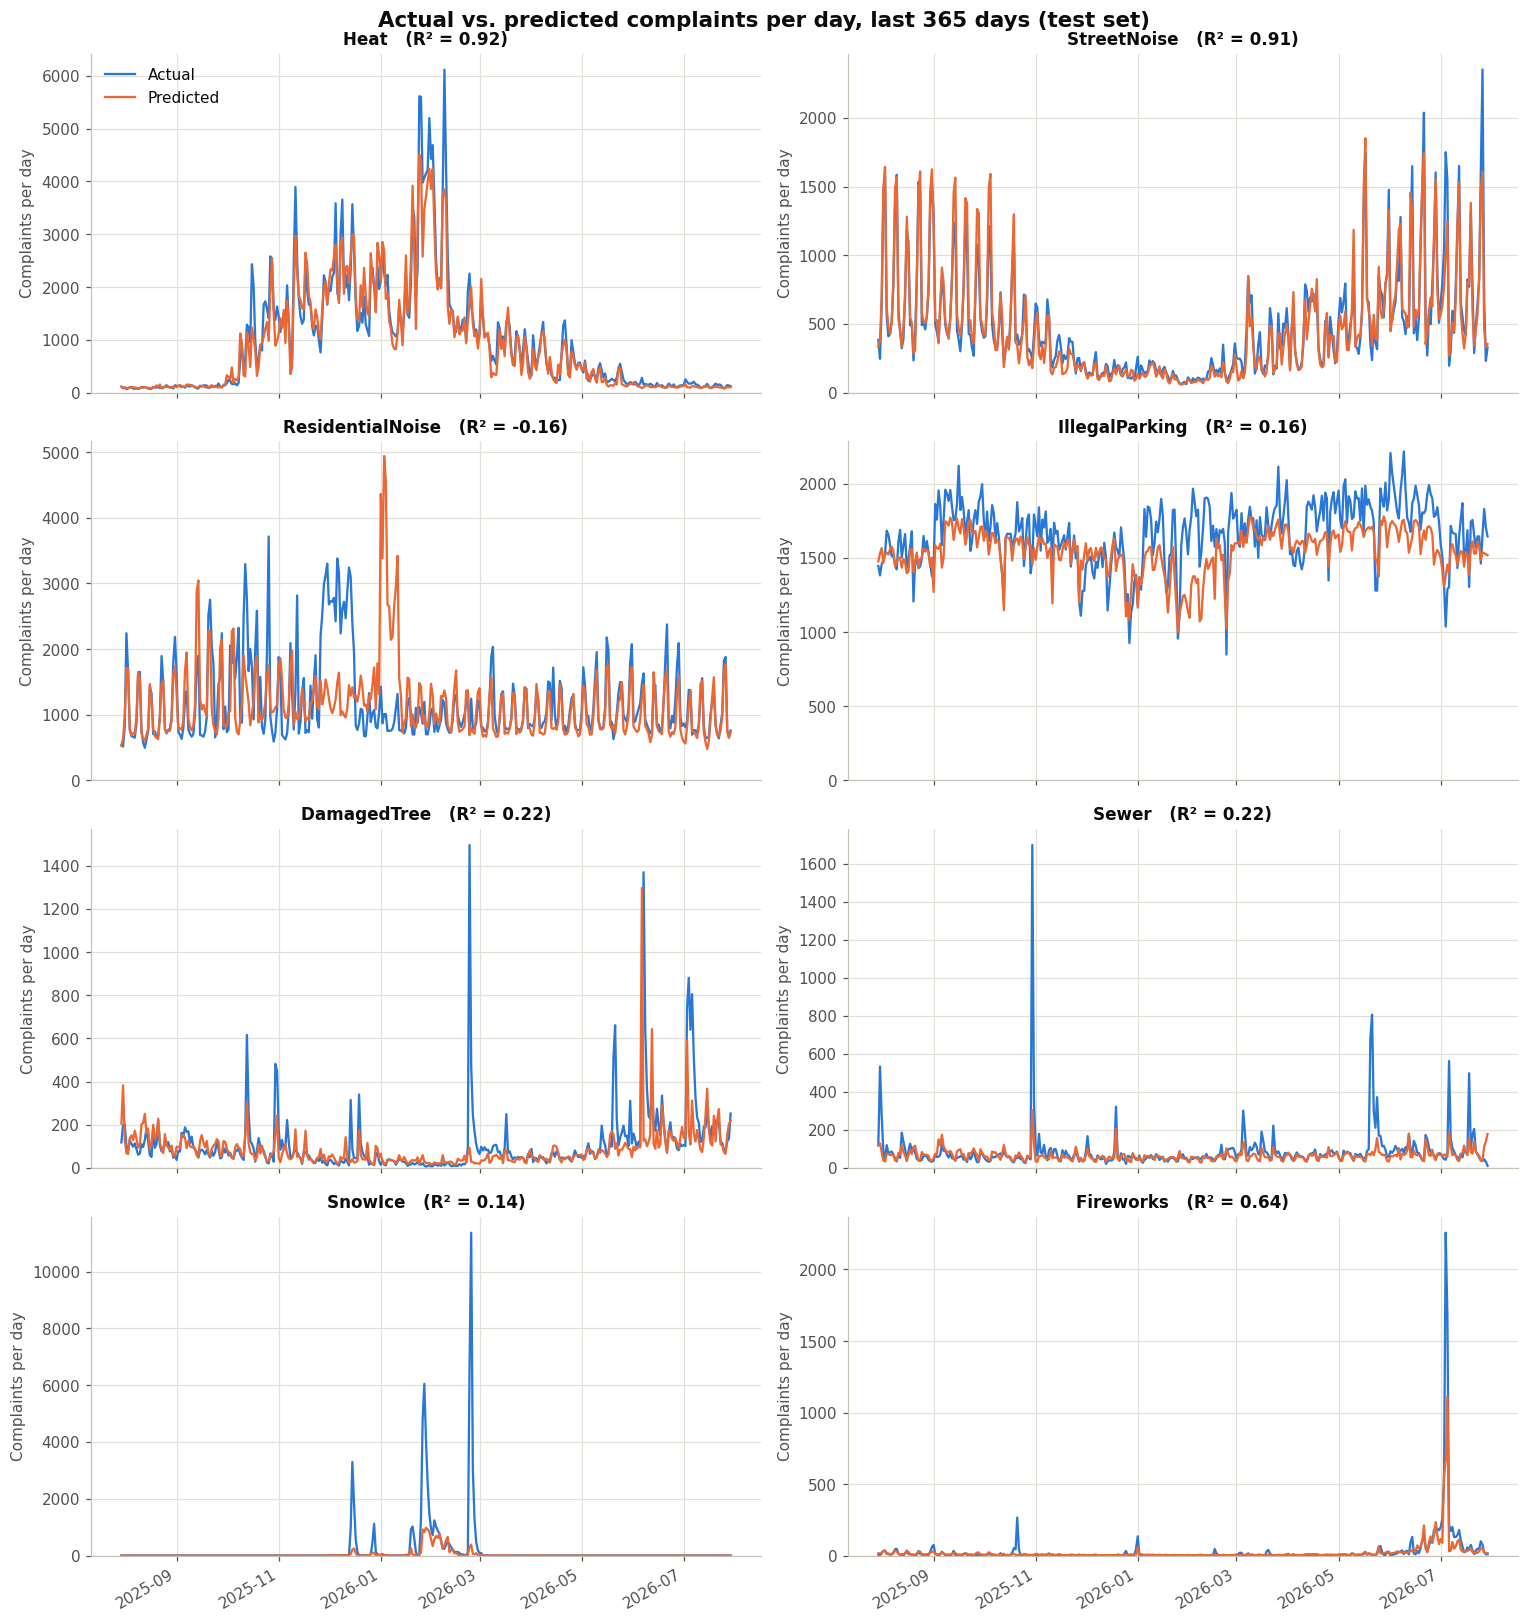

In [210]:
fig, axes = plt.subplots(4, 2, figsize=(14, 15), sharex=True)

for ax, complaint_type in zip(axes.flat, TYPES):
    ax.plot(test["date"], test[complaint_type], color=BLUE, linewidth=1.5, label="Actual")
    ax.plot(predictions["date"], predictions[complaint_type], color=ORANGE, linewidth=1.5, label="Predicted")
    ax.set_title(f"{complaint_type}   (R² = {scores.loc[complaint_type, 'R²']:.2f})", fontsize=11)
    ax.set_ylabel("Complaints per day")
    ax.set_ylim(bottom=0)

axes[0, 0].legend(loc="upper left")
fig.suptitle("Actual vs. predicted complaints per day, last 365 days (test set)", fontsize=14, fontweight="bold")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### Predict a given day

`predict_day` returns the model's prediction for every complaint type on one date, next to what actually happened.
Below it is used on three test-set days the models never saw: the snowiest, the wettest, and the hottest.

In [211]:
def predict_day(date):
    day = daily[daily["date"] == pd.Timestamp(date)]
    result = pd.DataFrame(index=TYPES)
    result["predicted"] = [models[complaint_type].predict(day[FEATURES])[0] for complaint_type in TYPES]
    result["actual"] = day[TYPES].iloc[0].values
    return result.round(0).astype(int)


example_days = {
    "Snowiest day": test.loc[test["snowfall_in"].idxmax(), "date"],
    "Wettest day": test.loc[test["precip_in"].idxmax(), "date"],
    "Hottest day": test.loc[test["max_temp_F"].idxmax(), "date"],
}

for label, date in example_days.items():
    day = daily[daily["date"] == date].iloc[0]
    print(f"{label}: {date.date()} ({day['day_name']}) - snow {day['snowfall_in']:.1f} in, "
          f"precipitation {day['precip_in']:.2f} in, high {day['max_temp_F']:.0f}°F")
    display(predict_day(date))

Snowiest day: 2026-01-25 (Sunday) - snow 11.4 in, precipitation 1.80 in, high 22°F


,predicted,actual
Heat,4364,5601
StreetNoise,87,91
ResidentialNoise,1434,1023
IllegalParking,1000,956
DamagedTree,39,15
Sewer,59,34
SnowIce,117,1315
Fireworks,3,1


Wettest day: 2025-10-30 (Thursday) - snow 0.0 in, precipitation 1.83 in, high 63°F


,predicted,actual
Heat,890,1378
StreetNoise,178,245
ResidentialNoise,1110,718
IllegalParking,1456,1482
DamagedTree,154,482
Sewer,304,1698
SnowIce,0,0
Fireworks,5,2


Hottest day: 2026-07-02 (Thursday) - snow 0.0 in, precipitation 0.00 in, high 100°F


,predicted,actual
Heat,158,252
StreetNoise,629,801
ResidentialNoise,560,808
IllegalParking,1416,1508
DamagedTree,136,102
Sewer,65,60
SnowIce,0,0
Fireworks,89,257


## 8. Most important features

XGBoost measures how much each feature improves the model's predictions (**gain**).
The importances for each model add up to 1.
Features that carry similar information (like the three temperature columns, or month and day of year)
share the credit between them.

In [212]:
importance = pd.DataFrame(
    {complaint_type: models[complaint_type].feature_importances_ for complaint_type in TYPES},
    index=FEATURES,
)
importance.round(3)

,Heat,StreetNoise,ResidentialNoise,IllegalParking,DamagedTree,Sewer,SnowIce,Fireworks
avg_temp_F,0.350,0.133,0.024,0.010,0.033,0.009,0.060,0.225
max_temp_F,0.382,0.231,0.027,0.010,0.015,0.009,0.064,0.192
min_temp_F,0.060,0.024,0.028,0.023,0.131,0.015,0.024,0.036
precip_in,0.003,0.025,0.019,0.018,0.018,0.086,0.006,0.005
trace_precip,0.008,0.007,0.014,0.002,0.021,0.004,0.008,0.002
snowfall_in,0.004,0.001,0.009,0.012,0.002,0.002,0.021,0.001
trace_snow,0.004,0.002,0.009,0.007,0.002,0.002,0.008,0.000
snow_depth_in,0.005,0.001,0.008,0.052,0.004,0.001,0.630,0.001
avg_wind_mph,0.006,0.008,0.014,0.008,0.009,0.008,0.011,0.017
max_gust_mph,0.006,0.008,0.016,0.008,0.119,0.012,0.006,0.010


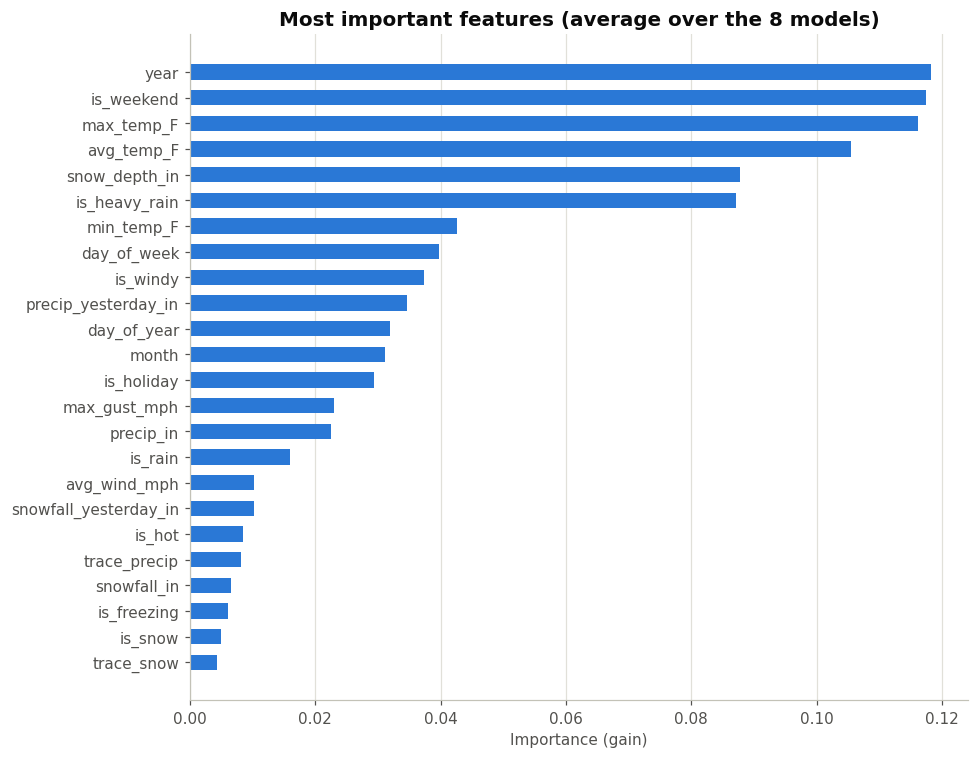

In [213]:
# Average importance across the 8 models
average_importance = importance.mean(axis=1).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(average_importance.index, average_importance.values, color=BLUE, height=0.6)
ax.set_title("Most important features (average over the 8 models)")
ax.set_xlabel("Importance (gain)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

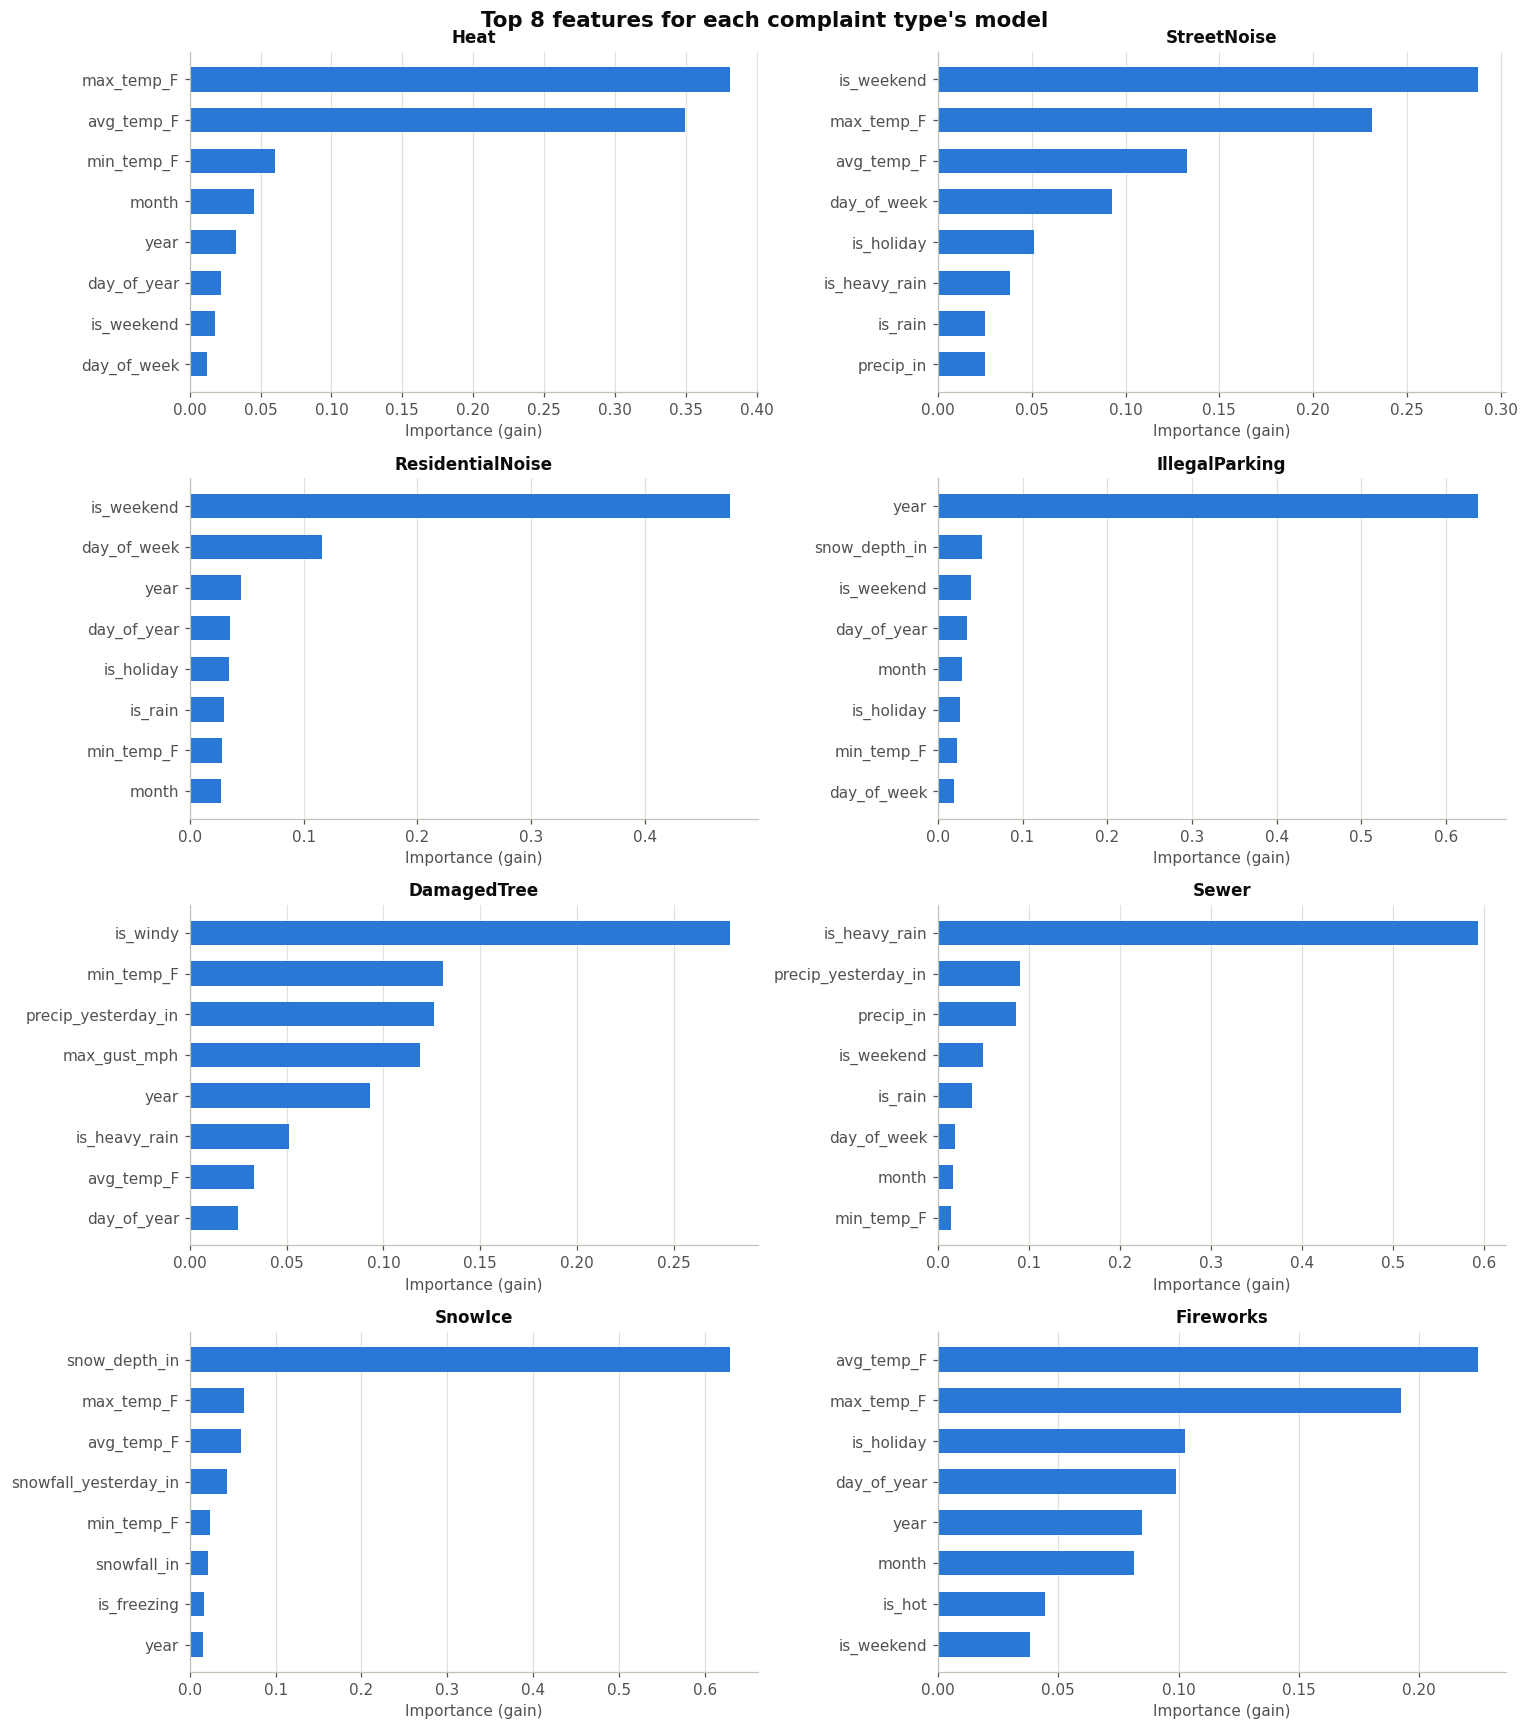

In [214]:
# Top 8 features for each complaint type's model
fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for ax, complaint_type in zip(axes.flat, TYPES):
    top_features = importance[complaint_type].sort_values().tail(8)
    ax.barh(top_features.index, top_features.values, color=BLUE, height=0.6)
    ax.set_title(complaint_type, fontsize=11)
    ax.set_xlabel("Importance (gain)")
    ax.grid(axis="y", visible=False)

fig.suptitle("Top 8 features for each complaint type's model", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

## 9. Key takeaways

**How many:** Together the 8 types are 40% of the 21.9 million complaints from Jan 2020 to Jul 2026. IllegalParking (13.0%) and
ResidentialNoise (11.4%) are the biggest. The storm-related types are much smaller: DamagedTree 1.1%, Sewer 0.9%, Fireworks 0.6%, SnowIce 0.4%.

**Temperature**
* **Heat** is by far the most temperature-driven type (r = −0.81): about 4,200 complaints a day at 15–20°F, compared with about 100 a day above 70°F.
* **StreetNoise** rises strongly in warm weather (r = 0.63), from under 100 a day below 25°F to about 850 a day at 75–80°F.
* **DamagedTree** goes from about 20–40 a day below 30°F to about 200 a day at 70–85°F, and **SnowIce** only shows up below about 40°F.
  Their correlations are weak (0.16 and −0.20) because most of their complaints come on a few storm days.
* **ResidentialNoise** (r = 0.12), **IllegalParking** (0.09), and **Sewer** (0.13) barely change with temperature.

**Weather conditions** (vs. normal-weather days)
* Each storm type reacts to the weather we expected. **SnowIce**: 64× on freezing days and 32× on snow days. **Sewer**: 5.0× on heavy-rain days
  and 1.6× on rainy days. **DamagedTree**: 4.5× on windy days and 2.5× on heavy-rain days.
* **Heat** is 4.9× on freezing days, 2.9× on snow days, and 2.0× on windy days (most windy days are in the winter). Hot days bring only 0.18×.
* **Fireworks** (3.7×) and **StreetNoise** (1.4×) go up on hot days. StreetNoise falls 80–84% on snowy and freezing days.
* **ResidentialNoise** and **IllegalParking** barely react to the weather (0.82–0.96), so they are mostly driven by the calendar.

**Day of the week:** StreetNoise, ResidentialNoise, and Fireworks are weekend complaints (about 1.5–1.7× on Saturday and Sunday).
DamagedTree and Sewer drop 29–39% on weekends. Heat and IllegalParking barely change. SnowIce jumps around because it depends on which days the few big storms fell on.

**Holidays:** Fireworks is 5.5× on holidays, almost all from July 4th. Both Noise types rise about 20% (like a weekend),
and Sewer, DamagedTree, and IllegalParking fall 13–24%. Heat is 15% higher only because most holidays are in the winter months (section 6c).

**Month:** Heat ranges from 2.36× in January to 0.12× in August, and SnowIce only appears from December to February.
Fireworks is 4–5× in June and July and below 0.35× in every other month. DamagedTree peaks in August (3.3×, including Tropical Storm Isaias in Aug 2020),
and Sewer peaks in September (1.8×, including the remains of Hurricane Ida in Sept 2021).

**XGBoost model**
* It works well for the types with a smooth seasonal pattern: **Heat** (R² = 0.92), **StreetNoise** (0.91), and **Fireworks** (0.64).
* The storm types are hard to predict (DamagedTree 0.22, Sewer 0.22, SnowIce 0.14). The model gets the direction right, but it badly underestimates the
  biggest storms. For example, on Oct 30, 2025 (1.83 inches of rain) it predicted 304 sewer complaints and there were 1,698, and on the snowiest
  test day it predicted 117 SnowIce complaints and there were 1,315. A few storms like these make up a big part of these types' complaints.
* **IllegalParking** (0.16) grows every year (about 530 a day in 2020 to 1,720 in 2026), and a tree model cannot predict levels higher than anything
  it was trained on. On a typical day it is still only off by about 9%.
* **ResidentialNoise** (−0.16) had bursts in fall 2025 that the model did not predict, and the model predicted a big New Year's spike
  (based on earlier years) that did not happen.

**Most important features:** For these 8 types, weather matters about as much as the calendar. Overall the top features are `year`,
`is_weekend`, and the temperature columns.
* **The 0/1 weather condition columns are the top features for two of the storm types:** `is_heavy_rain` has 59% of Sewer's importance,
  and `is_windy` is DamagedTree's top feature (28%). This makes the models easy to read ("heavy rain drives sewer complaints").
  They don't add new information, though: each one is built from a raw weather column the model already has (for example, `is_heavy_rain` is
  `precip_in` ≥ 1 with no snow), so a tree could make the same split by itself.
* **SnowIce** depends mostly on **snow on the ground** (`snow_depth_in`, 63%), not on the snowfall that day: people report snow and ice in the days after a storm.
* **Heat** depends mostly on temperature (79%), **ResidentialNoise** on the weekend (48%), and **IllegalParking** on the year (64%).

*Caveat:* the rate ratios are simple comparisons that don't adjust for other factors. For example, part of the "snow" effect
is really a "winter" effect.